# Example: Implicit odd Grad–Shafranov response

This example calculates the response of a symmetric, manufactured plasma current distribution to antisymmetric external ring currents. All inputs are created below; no machine files are needed. We compare the implicit linear response with independent nonlinear equilibria and plot their agreement.

FreeGS4E 0.15 provides the spatial inverse on a uniform rectangular grid. The response routine accepts an inverse callback and does not depend on that grid representation.

---
## Import packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root
from freegs4e.gradshafranov import Greens, mu0
from freegs4e.gs_solver import GSDSTSolver
from freegsnke.gs_response import solve_odd_response
%matplotlib inline

## Build the free-boundary flux map

Let $G:j_\phi\mapsto\psi_{\rm pl}$ solve
$$\Delta^*\psi_{\rm pl}=-\mu_0 Rj_\phi.$$
The boundary flux is a direct Green-function sum over the interior current. Area weights are $dR\,dZ$, without $2\pi R$. Flux is measured in Wb/rad and current density in A/m$^2$.

Reflection across $Z=0$ is represented by the index permutation $P$; the odd projection is $P_o=(I-P)/2$.

In [2]:
r, z = np.linspace(1, 3, 17), np.linspace(-1, 1, 17)
R, Z = np.meshgrid(r, z, indexing="ij")
shape = R.shape
reflection = np.arange(R.size).reshape(shape)[:, ::-1].ravel()
odd = lambda field: (field - field[reflection]) / 2
area = (r[1] - r[0]) * (z[1] - z[0])
boundary = np.zeros(shape, dtype=bool)
boundary[[0, -1], :] = True
boundary[:, [0, -1]] = True
interior = ~boundary
solver = GSDSTSolver(R, Z, order=2)
# The source vanishes at the computational boundary. The full Green sum
# below supplies free-boundary flux; it makes no symmetry approximation.
green = (
    Greens(
        R[boundary, None],
        Z[boundary, None],
        R[interior][None, :],
        Z[interior][None, :],
    )
    * area
)

def inverse(current):
    j = np.asarray(current).reshape(shape)
    # Upstream uses +Delta*: negative interior source, positive edge flux.
    rhs = -mu0 * R * j
    rhs[boundary] = green @ j[interior]
    return solver(np.zeros(shape), rhs).ravel()

## Define a symmetric manufactured equilibrium

The Gaussian current envelope defines $j_0$ and $\psi_0=Gj_0$. Opposite ring currents at $(R,Z)=(3.5,\pm0.8)$ m produce an odd applied flux $Ig$, where $I$ is in amperes and $g$ is in Wb/rad/A.

We choose the smooth source law
$$j(\psi,I)=j_0+C(\psi+Ig-\psi_0)+\beta(\psi+Ig-\psi_0)^3.$$
Here $\psi$ denotes plasma flux, so the source responds to the total flux $\psi+Ig$. The cubic term makes the finite-amplitude response nonlinear while leaving the base derivative equal to $C$.

This is a manufactured differentiation test, rather than a normalized-flux pressure/current profile model.

In [3]:
envelope = np.exp(-(((R - 2) / 0.35) ** 2) - (Z / 0.4) ** 2)
envelope[boundary] = 0
envelope = envelope.ravel()
j0 = 1e6 * envelope
psi0 = inverse(j0)
# Opposite external unit ring currents give odd applied flux per ampere.
g = odd((Greens(3.5, 0.8, R, Z) - Greens(3.5, -0.8, R, Z)).ravel())
coefficient = 1e5 * envelope
cubic = 0.1 * coefficient / np.ptp(psi0) ** 2

def current(psi, amplitude):
    # The manufactured source has equilibrium (psi0,j0) at amplitude zero.
    # Its derivative there is coefficient; the cubic term exercises the
    # difference between a finite perturbation and the implicit tangent.
    displacement = psi + amplitude * g - psi0
    return j0 + coefficient * displacement + cubic * displacement**3

def residual(psi, amplitude):
    return psi - inverse(current(psi, amplitude))

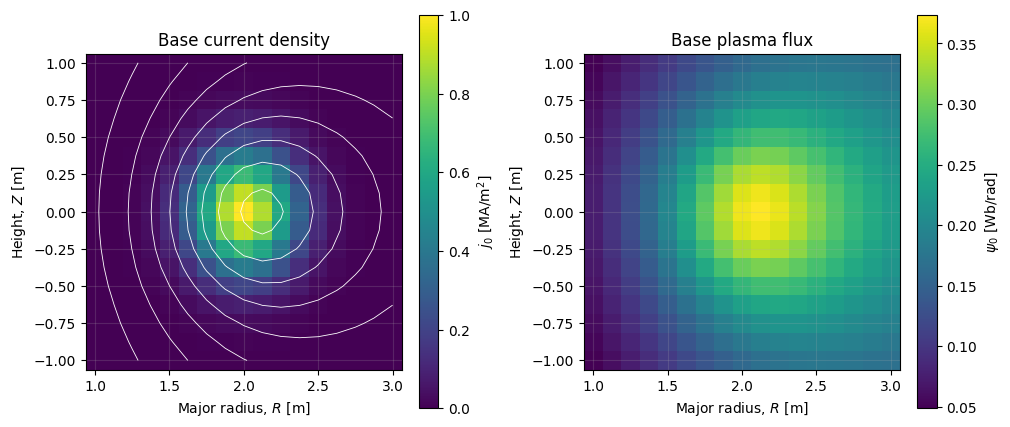

In [4]:
# Use the same R–Z axes and equal physical aspect ratio in every field plot.
def field_plot(ax, values, title, units, odd_field=False):
    values = np.asarray(values).reshape(shape)
    options = {}
    if odd_field:
        limit = np.max(np.abs(values))
        options = dict(cmap="RdBu_r", vmin=-limit, vmax=limit)
    artist = ax.pcolormesh(R, Z, values, shading="auto", **options)
    ax.set(title=title, xlabel=r"Major radius, $R$ [m]", ylabel=r"Height, $Z$ [m]")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.figure.colorbar(artist, ax=ax, label=units, shrink=0.8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
field_plot(axes[0], j0 / 1e6, "Base current density", r"$j_0$ [MA/m$^2$]")
field_plot(axes[1], psi0, "Base plasma flux", r"$\psi_0$ [Wb/rad]")
axes[0].contour(R, Z, psi0.reshape(shape), levels=8, colors="white", linewidths=0.6)
plt.show()

## Solve the implicit odd response

Differentiating the equilibrium equation at $I=0$ gives
$$(I-P_oGCP_o)v=P_oG(Cg),\qquad j_I=P_o[C(v+g)],$$
where $v=\partial\psi_{\rm pl}/\partial I$ and $j_I=\partial j_\phi/\partial I$. The plasma current responds to $v+g$. Matrix-free GMRES evaluates the operator through the inverse callback.

The reduced equation requires an even base and coefficient $C$, odd forcing $g$, and a reflection-equivariant inverse. Input parity checks cannot establish these assumptions for an arbitrary physical model. Scalar normalization and critical-flux terms cancel only under the corresponding symmetry assumptions; sharp interfaces or critical-point switching need separate treatment.

In [5]:
response = solve_odd_response(inverse, coefficient, g, reflection)
dj = response["current_response"]

print(f"Tangent relative residual: {response['relative_residual']:.3e}")

Tangent relative residual: 9.980e-11


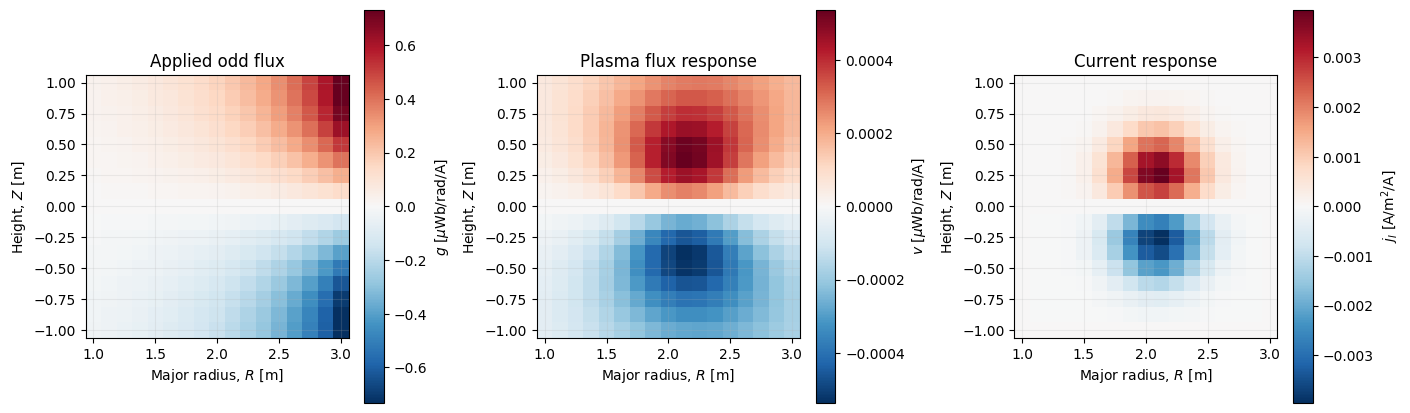

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), constrained_layout=True)
field_plot(axes[0], g * 1e6, "Applied odd flux", r"$g$ [$\mu$Wb/rad/A]", True)
field_plot(axes[1], response["plasma_response"] * 1e6, "Plasma flux response", r"$v$ [$\mu$Wb/rad/A]", True)
field_plot(axes[2], dj, "Current response", r"$j_I$ [A/m$^2$/A]", True)
plt.show()

## Verify against signed nonlinear equilibria

For each amplitude $h$, solve the full nonlinear equation independently at $I=+h$ and $I=-h$, checking both equilibrium residuals. The central difference
$$j_I^{(h)}=P_o\frac{j(+h)-j(-h)}{2h}$$
should approach the implicit tangent with $O(h^2)$ error. The grid remains fixed throughout this check.

In [7]:
checks = []
for step in (4000.0, 2000.0, 1000.0):
    currents = []
    for sign in (1, -1):
        amplitude = sign * step
        guess = psi0 + amplitude * response["plasma_response"]
        solved = root(
            lambda psi: residual(psi, amplitude),
            guess,
            method="hybr",
            options={"xtol": 1e-10},
        )
        error = np.linalg.norm(residual(solved.x, amplitude)) / np.linalg.norm(psi0)
        if not np.isfinite(error) or error > 1e-11:
            raise RuntimeError("Nonlinear perturbed solve failed")
        currents.append(current(solved.x, amplitude))
    # Central differences have O(step**2) truncation error for a smooth
    # source. Explicit odd projection matches the sector solved above.
    fd = odd((currents[0] - currents[1]) / (2 * step))
    checks.append(
        dict(
            step_A=step,
            relative_current_error=float(
                np.linalg.norm(fd - dj) / np.linalg.norm(dj)
            ),
        )
    )
if checks[-1]["relative_current_error"] >= checks[0]["relative_current_error"] / 8:
    raise RuntimeError("Signed nonlinear checks did not approach the tangent")

for check in checks:
    print(f"h = {check['step_A']:7.0f} A: relative current error = {check['relative_current_error']:.3e}")

h =    4000 A: relative current error = 1.753e-07
h =    2000 A: relative current error = 4.383e-08
h =    1000 A: relative current error = 1.096e-08


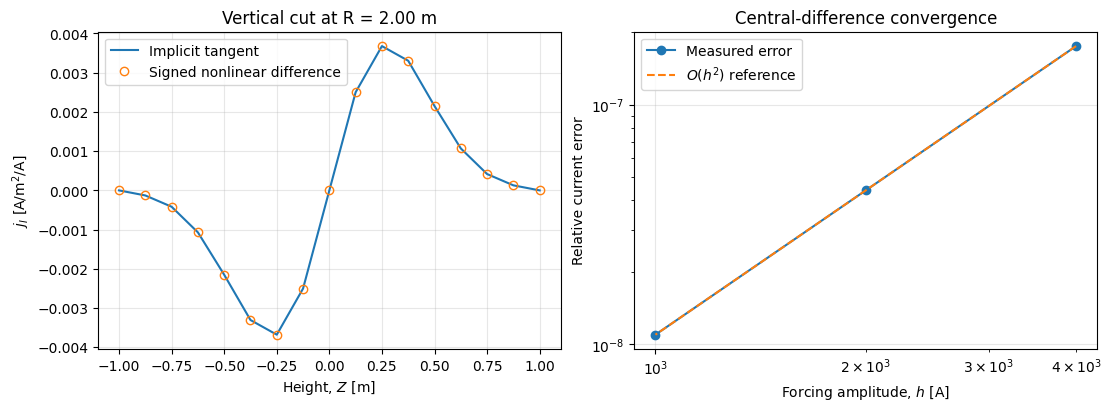

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
# The last finite difference uses the smallest amplitude. A vertical cut
# through the envelope centre displays the odd spatial response directly.
i = np.argmin(np.abs(r - 2.0))
axes[0].plot(z, dj.reshape(shape)[i], label="Implicit tangent")
axes[0].plot(z, fd.reshape(shape)[i], "o", fillstyle="none", label="Signed nonlinear difference")
axes[0].set(xlabel=r"Height, $Z$ [m]", ylabel=r"$j_I$ [A/m$^2$/A]", title=f"Vertical cut at R = {r[i]:.2f} m")
axes[0].legend()
steps = np.array([item["step_A"] for item in checks])
errors = np.array([item["relative_current_error"] for item in checks])
axes[1].loglog(steps, errors, "o-", label="Measured error")
axes[1].loglog(steps, errors[0] * (steps / steps[0])**2, "--", label=r"$O(h^2)$ reference")
axes[1].set(xlabel=r"Forcing amplitude, $h$ [A]", ylabel="Relative current error", title="Central-difference convergence")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.show()

## Illustrative incremental linkage

Reciprocity gives $K=2\pi\sum_i g_iw_i(j_I)_i$, with $w_i=dR\,dZ$. The factor $2\pi$ converts per-radian flux to linkage. This is a coupling diagnostic; no conductor dynamics model is included.

In [9]:
linkage = float(2 * np.pi * area * np.dot(g, dj))
print(f"Incremental linkage: {linkage:.6e} H")

Incremental linkage: 1.270393e-09 H


The factor-of-four error reduction on halving the forcing amplitude verifies differentiation on this fixed discretization. It does not establish spatial convergence or predict vertical instability. The accompanying unit tests additionally compare the tangent against an independently assembled dense solve and check invalid forcing and a singular response equation.